In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("../data/orders_joined.csv")
d = orders["delivery_days"]
real = d[d != -999]

for name, col in [("with the five", d), ("without them", real)]:
    print(f"{name:14s} mean {col.mean():6.3f}   sd {col.std():6.3f}   "
          f"z of 5 days {(5 - col.mean()) / col.std():+.4f}")

with the five  mean  0.981   sd 50.166   z of 5 days +0.0801
without them   mean  3.492   sd  2.033   z of 5 days +0.7416


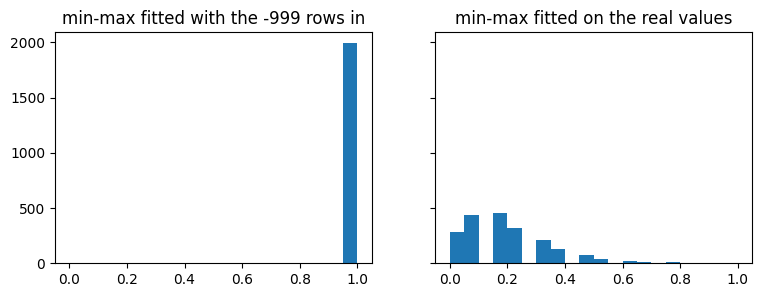

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].hist((real - d.min()) / (d.max() - d.min()), bins=20, range=(0, 1))
axes[0].set_title("min-max fitted with the -999 rows in")
axes[1].hist((real - real.min()) / (real.max() - real.min()), bins=20, range=(0, 1))
axes[1].set_title("min-max fitted on the real values")
Path("../outputs").mkdir(exist_ok=True)
fig.savefig("../outputs/delivery_minmax.png", dpi=150, bbox_inches="tight")